# M01-2 | prepare / convert 到底改了圖的哪裡

M01-1 看的是 stem 那一小段。這本 notebook 換成一個完整的小 residual block，
把 `prepare_pt2e` 與 `convert_pt2e` 對圖的每一個改動都攤開。

先預測，再往下執行看答案：

1. conv2d 和 relu 中間，會不會有 observer？
2. `max_pool2d` 的輸入與輸出，會用同一組 qparams 嗎？
3. `cat` 的兩個輸入呢？

In [1]:
import copy

import torch

from common.graph_utils import annotation_table, diff_ops, observer_placement_table, unannotated_ops
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. residual block 的三個階段

模型是 `conv → bn → relu → conv → bn`，再和輸入 `x` 相加後過 relu。
conv → bn → relu 怎麼變，M01-1 已經看過；這裡只畫 residual 特有的部分：輸入 `x` 同時餵給第一個 conv 和 `add`。

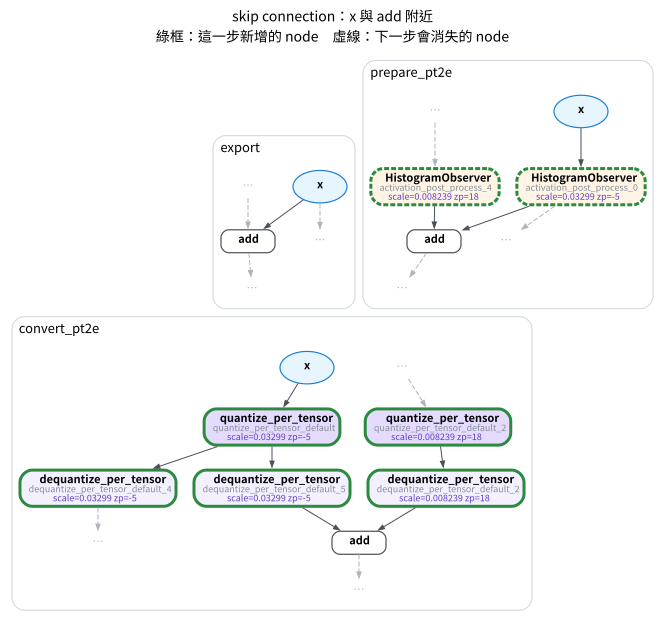

In [2]:
model = get_model("residual", ch=8).eval()
ex = (torch.randn(4, 8, 16, 16),)
gm = export_module(model, ex)

quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
with torch.no_grad():
    for _ in range(8):
        prepared(torch.randn(4, 8, 16, 16))
converted = convert_pt2e(copy.deepcopy(prepared))

draw_stages([(gm, "export"), (prepared, "prepare_pt2e"), (converted, "convert_pt2e")],
            focus=["x", "add"], hops=0, title="skip connection：x 與 add 附近")

依 export → prepare_pt2e（第一個 row）→ convert_pt2e（第二個 row）的順序讀：

- **prepare**：`x` 後面只插**一個** observer，同時供 conv 和 add 使用；`add` 的另一個輸入（第二個 conv 的輸出）有自己的 observer。
- **convert**：observer 換成 `quantize` → `dequantize`。`x` 的那個 quantize 後面接了兩個 dequantize，一個 consumer 一個。
  這是 `convert_pt2e` 最後跑的 `DuplicateDQPass` 做的（torchao 0.18 原始碼
  [`duplicate_dq_pass.py`](https://github.com/pytorch/ao/blob/main/torchao/quantization/pt2e/quantizer/duplicate_dq_pass.py)）：
  每條分支有自己的 dq，後端把「dq → op → q」換成 int8 kernel 時才能各自處理（為什麼共用的 dq 不行，M02-3 會實際驗證）。

整張圖的變化用 op 數量的增減來看：兩個 `batch_norm` 消失（折進 conv），多出 observer；
convert 之後 observer 全部換成 q/dq。weight 的 observer 只剩 `dequantize_per_channel`，因為 int8 weight 直接存成常數。

In [3]:
table(diff_ops(gm, prepared, "export", "prepare", tablefmt="html"))

op,export,prepare,delta
<module:HistogramObserver>,0,4,4
<module:PerChannelMinMaxObserver>,0,2,2
batch_norm,2,0,-2
add,1,1,0
conv2d,2,2,0
relu,2,2,0


In [4]:
table(diff_ops(prepared, converted, "prepare", "convert", tablefmt="html"))

op,prepare,convert,delta
<module:HistogramObserver>,4,0,-4
<module:PerChannelMinMaxObserver>,2,0,-2
dequantize_per_channel,0,2,2
dequantize_per_tensor,0,5,5
quantize_per_tensor,0,4,4
add,1,1,0
conv2d,2,2,0
relu,2,2,0


每個 observer 掛在哪條邊上、校準後算出什麼 qparams：

In [5]:
table(observer_placement_table(prepared, tablefmt="html"))

observer,type,輸入來自,輸出給,qparams
activation_post_process_1,PerChannelMinMaxObserver,conv1_weight,conv2d,"scale=0.0009225 zp=0 (per-channel, n=8)"
activation_post_process_3,PerChannelMinMaxObserver,conv2_weight,conv2d_1,"scale=0.0009054 zp=0 (per-channel, n=8)"
activation_post_process_0,HistogramObserver,x,"conv2d, add",scale=0.03299 zp=-5
activation_post_process_2,HistogramObserver,relu,conv2d_1,scale=0.008802 zp=-128
activation_post_process_4,HistogramObserver,conv2d_1,add,scale=0.008239 zp=18
activation_post_process_5,HistogramObserver,relu_1,output,scale=0.01745 zp=-128


**答案 1**：conv2d 的輸出直接進 relu，中間沒有 observer。
quantizer 把 conv + relu 標成一組，只量化 relu 的輸出；後端才能把兩者融成一個 kernel，
中間的值也不必先存成 int8（M04 細講）。

In [6]:
def users_of(gm, name):
    node = next(n for n in gm.graph.nodes if n.name == name)
    return [u.name for u in node.users]


print("prepare 之後 conv2d 的使用者：", users_of(prepared, "conv2d"))
assert users_of(prepared, "conv2d") == ["relu"]

prepare 之後 conv2d 的使用者： ['relu']


## B. quantizer 到底管了哪些 op

問題 2、3 換一個有 `cat`、`max_pool2d`、`mean` 的模型（`CatPoolNet`）：

```
x ─┬─ conv a → relu ─┐
   └─ conv b → relu ─┴─ cat → max_pool2d → conv out ─┬──────── add → 輸出
                                                     └─ mean ──┘
```

要回答「管了哪些 op」，得先看 quantizer 在圖上留下了什麼。先大概認識兩個名詞：

- **Quantizer**：後端提供的物件，負責決定「哪些 tensor 要量化、用什麼規格量化」。
  本章一直在用的 `XNNPACKQuantizer` 就是 XNNPACK 後端的 quantizer。
- **`quantizer.annotate(圖)`**：quantizer 的核心方法。它走過整張圖，在要量化的 node 上寫一份**標註**，
  存在 `node.meta["quantization_annotation"]`。標註有兩個欄位：
  `input_qspec_map` 記「哪幾條輸入邊要量化、各用哪份規格」，`output_qspec` 記「這個 node 的輸出要不要量化、用哪份規格」。
  一份規格（`QuantizationSpec`）寫的是 dtype、整數範圍、對稱或非對稱、per-tensor 或 per-channel，以及用哪種 observer。

`annotate` 只貼標註，不插 observer、也不改圖的結構。平常不必自己呼叫：`prepare_pt2e` 的第一步就是呼叫它，
再照標註插 observer。這裡單獨呼叫，是為了在 observer 出現之前先看標註本身。
`annotate` 也會原地修改，所以對複本呼叫。

> **先別擔心細節。** 這裡只需要看懂「哪些 node 有標註、哪些沒有」。quantizer 與 `annotate` 後面會分幾本 notebook 詳細說明：
>
> - M03-1：`prepare_pt2e` 怎麼依標註決定 observer 插在哪條邊上
> - M03-2：逐一讀懂 `XNNPACKQuantizer` 貼的每一份標註
> - M03-3：自己從零寫一個 quantizer 的 `annotate`
> - M03-4、M03-5：`SharedQuantizationSpec`（共用 qparams）、`DerivedQuantizationSpec`（由其他 scale 推導）等其他規格
> - M10-1：把硬體的限制寫成一個完整的 quantizer

In [7]:
gm2 = export_module(get_model("cat_pool").eval(), example_inputs(4))
q2, _ = get_xnnpack_quantizer(is_per_channel=True)
annotated = q2.annotate(copy.deepcopy(gm2))
table(annotation_table(annotated, tablefmt="html"))

node,target,input_qspec_map,output_qspec
a_weight,a.weight,-,NoneType
a_bias,a.bias,-,NoneType
b_weight,b.weight,-,NoneType
b_bias,b.bias,-,NoneType
out_weight,out.weight,-,NoneType
out_bias,out.bias,-,NoneType
conv2d,conv2d,"x:Spec, a_weight:Spec, a_bias:NoneType",NoneType
relu,relu,-,Spec
conv2d_1,conv2d,"x:Spec, b_weight:Spec, b_bias:NoneType",NoneType
relu_1,relu,-,Spec


表的讀法：

- `Spec` 是一份獨立的量化規格，`SharedSpec` 表示「和另一處共用 qparams」，`NoneType` 表示這個位置不量化。
  例如 `conv2d` 的輸出是 `NoneType`，因為它和後面的 relu 是一組，只量化 relu 的輸出（答案 1 的原因）。
- weight、bias 那幾個 row 沒有規格：quantizer 只是把它們標成「已處理」。weight 的規格寫在使用它的 conv 那一個 row 的 `input_qspec_map` 裡；
  bias 在那裡是 `NoneType`，這份 config 不量化 bias。

`cat` 和 `max_pool2d` 不在表上：它們完全沒被標註，會留在 fp32。

In [8]:
left_fp32 = [n.name for n in unannotated_ops(annotated)]
print("沒被標註的 op：", left_fp32)
assert set(left_fp32) == {"cat", "max_pool2d"}

沒被標註的 op： ['cat', 'max_pool2d']


插 observer 之後看 `cat` 附近：兩個 relu 的輸出各有自己的 observer，
`cat` 與 `max_pool2d` 之間沒有 observer。

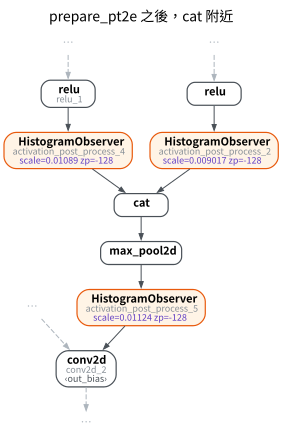

In [9]:
prepared2 = prepare_pt2e(gm2, q2)
with torch.no_grad():
    for _ in range(8):
        prepared2(torch.randn(4, 3, 16, 16))
draw(prepared2, focus=["cat", "max_pool2d"], hops=2, title="prepare_pt2e 之後，cat 附近")

**答案 2、3**：在這個環境裡，`cat` 的兩個輸入各用各的 qparams（上圖兩個 observer 的 scale 不同），
`max_pool2d` 也沒有量化。

這不是設計，而是 quantizer 靜默失效。本專案 M01～M07 用的是 **torchao 測試版**的 `XNNPACKQuantizer`
（`torchao.testing.pt2e._xnnpack_quantizer`，torchao 為自己的單元測試留的拷貝）。
它找 `cat` 的方法依賴 `node.meta["source_fn_stack"]`，但 torch 2.14 export 出來的 node 已經沒有這個欄位：

In [10]:
cat_node = next(n for n in gm2.graph.nodes if n.name == "cat")
print(sorted(cat_node.meta))
assert "source_fn_stack" not in cat_node.meta

['from_node', 'nn_module_stack', 'stack_trace', 'tensor_meta', 'torch_fn', 'val']


`max_pool2d` 沒有自己的 annotator，它在最後一步「跟著輸入共用 qparams」；輸入 `cat` 沒標，它也就跟著沒標。
conv、linear、add 是直接比對 `node.target`，所以照常運作。
executorch 附的 `XNNPACKQuantizer` 沒有這個問題，M08 會拿兩份對照。

## 小結

- prepare 做兩件事：折 BN、依標註插 observer。convert 把 observer 換成 q/dq，weight 存成 int8 常數。
- conv + relu 中間沒有量化點，這是 PT2E 表達「融合」的方式。
- 「這個 op 有沒有被量化」一定要自己 dump annotation 驗證，不要只看文件或文章。